In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.colors as mplcolors
import matplotlib.ticker as ptick
import matplotlib.patches as patches
import matplotlib.patheffects as pe
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow

import time
import spiceypy as spice
import JupiterMag as jm
from CSField import CSField

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

jm.Internal.Config(Model='jrm33', Degree=1, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

spice.furnsh(
    '/Users/shin/Documents/Research/Jupiter/Codes/HST/kernel/cassMetaK.txt')
radii = spice.bodvrd("JUPITER", "RADII", 3)[1]
RJ_km = radii[0]
c = radii[2]
f = (RJ_km - c) / RJ_km

Importing Library
done


In [2]:
# ===========================================================
# CONSTANTS
# ===========================================================
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492.0E+3          # JUPITER RADIUS [m]


# ===========================================================
# CONFIGURE CSFIELD
# ===========================================================
csfield = CSField()
csfield.config(
    I_rho0=0.0,  # 8.3795
    i_phi0=4.91719E-5,
    a0=2.19129985E-6,
    MLT0=2.46607518
)

In [3]:
# ===========================================================
# FIELD LINE TRACE (DAWN)
# ===========================================================
r0 = np.array([5.9, 9.4, 15.0, 26.0, 50.0, 75.0])*RJ  # [m]
theta0 = np.radians(89.99)        # Colatitude [rad]
phi0 = np.radians(360.0-112.0)   # East longitude [rad]

x0 = r0*np.sin(theta0)*np.cos(phi0)
y0 = r0*np.sin(theta0)*np.sin(phi0)
z0 = r0*np.cos(theta0)

Niter = 80000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr0 = np.zeros((r0.size*2, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr0[j, 0, k] = x_cs/RJ
            result_arr0[j, 1, k] = y_cs/RJ
            result_arr0[j, 2, k] = z_cs/RJ
            # result_arr0[j, 0, k] = x/RJ
            # result_arr0[j, 1, k] = y/RJ
            # result_arr0[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break


# 南半球
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr0[j+x0.size, 0, k] = x_cs/RJ
            result_arr0[j+x0.size, 1, k] = y_cs/RJ
            result_arr0[j+x0.size, 2, k] = z_cs/RJ
            # result_arr0[j+x0.size, 0, k] = x/RJ
            # result_arr0[j+x0.size, 1, k] = y/RJ
            # esult_arr0[j+x0.size, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break

End altitude [km]: -49.11
End altitude [km]: -36.17
End altitude [km]: 5.9
End altitude [km]: 40.7
End altitude [km]: -21.84
End altitude [km]: -45.43
End altitude [km]: -12.67
End altitude [km]: -13.42
End altitude [km]: -45.65
End altitude [km]: -8.95
End altitude [km]: -23.21
End altitude [km]: -9.64


In [4]:
# ===========================================================
# FIELD LINE TRACE (DUSK)
# ===========================================================
r0 = np.array([5.9, 9.4, 15.0, 26.0, 50.0])*RJ  # [m]
theta0 = np.radians(89.99)        # Colatitude [rad]
phi0 = np.radians(360.0-112.0)   # East longitude [rad]

x0 = r0*np.sin(theta0)*np.cos(phi0)
y0 = r0*np.sin(theta0)*np.sin(phi0)
z0 = r0*np.cos(theta0)

Niter = 70000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr1 = np.zeros((r0.size*2, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr1[j, 0, k] = x_cs/RJ
            result_arr1[j, 1, k] = y_cs/RJ
            result_arr1[j, 2, k] = z_cs/RJ
            # result_arr1[j, 0, k] = x/RJ
            # result_arr1[j, 1, k] = y/RJ
            # esult_arr1[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break


# 南半球
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr1[j+x0.size, 0, k] = x_cs/RJ
            result_arr1[j+x0.size, 1, k] = y_cs/RJ
            result_arr1[j+x0.size, 2, k] = z_cs/RJ
            # result_arr1[j+x0.size, 0, k] = x/RJ
            # result_arr1[j+x0.size, 1, k] = y/RJ
            # result_arr1[j+x0.size, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2), i)
                break

End altitude [km]: 1.81
End altitude [km]: 5.64
End altitude [km]: 17.12
End altitude [km]: -29.87
End altitude [km]: 3.8
End altitude [km]: 46.9 2800
End altitude [km]: 54.99 3915
End altitude [km]: -52.39 5069
End altitude [km]: 34.33 6520
End altitude [km]: 53.33 8951


In [5]:
# ===========================================================
# FIELD LINE TRACE
# ===========================================================
r0 = 5.0*RJ  # [m]
# Colatitude [rad]
theta0 = np.radians(np.array([10.0, 20.0, 40.0, 60.0, 80.0]))
phi0 = np.radians(360.0-112.0)   # East longitude [rad]

x0 = r0*np.sin(theta0)*np.cos(phi0)
y0 = r0*np.sin(theta0)*np.sin(phi0)
z0 = r0*np.cos(theta0)

Niter = 70000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr3 = np.zeros((x0.size, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr3[j, 0, k] = x_cs/RJ
            result_arr3[j, 1, k] = y_cs/RJ
            result_arr3[j, 2, k] = z_cs/RJ
            # result_arr3[j, 0, k] = x/RJ
            # result_arr3[j, 1, k] = y/RJ
            # result_arr3[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude   [km]:', round(alt_gr, 2))
                print(
                    '--- latitude  [deg]:', round(np.mod(np.degrees(0.5*np.pi-theta), 360.0), 3))
                print(
                    '--- longitude [deg]:', round(np.mod(np.degrees(2*np.pi-phi), 360.0), 3))
                break

End altitude   [km]: -6.54
--- latitude  [deg]: 82.38
--- longitude [deg]: 161.792
End altitude   [km]: -52.95
--- latitude  [deg]: 79.07
--- longitude [deg]: 144.942
End altitude   [km]: 54.22
--- latitude  [deg]: 71.815
--- longitude [deg]: 132.8
End altitude   [km]: -25.17
--- latitude  [deg]: 65.733
--- longitude [deg]: 129.676
End altitude   [km]: 36.55
--- latitude  [deg]: 61.976
--- longitude [deg]: 130.017


In [6]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DUSK)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 17.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)
print(np.sqrt(x_cs0**2+y_cs0**2+z_cs0**2)/RJ)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

print(np.sqrt(x0**2+y0**2+z0**2)/RJ)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_N = np.zeros((x0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_N[j, 0, k] = x_cs/RJ
            result_arr_N[j, 1, k] = y_cs/RJ
            result_arr_N[j, 2, k] = z_cs/RJ
            # result_arr_N[j, 0, k] = x/RJ
            # result_arr_N[j, 1, k] = y/RJ
            # result_arr_N[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z > 45.0*RJ:
            print('North edge [km]:')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 45.0*RJ:
            print('Horizontal edge')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002
 1.002 1.002 1.002 1.002]
[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002
 1.002 1.002 1.002 1.002]
North edge [km]:
47.38934937891466 7.57392849334499
North edge [km]:
50.75822652624448 9.078778248226149
North edge [km]:
57.25298935193623 11.379033963204732
Horizontal edge
59.582224819468834 13.938160161854547
Horizontal edge
52.49411050365688 16.39763967705924
Horizontal edge
47.94095016177309 17.393776698716483
Horizontal edge
45.438178245349185 17.629400427129976
Horizontal edge
45.28981958934777 17.178279416313607
Jupiter surface
0.8992132220163767 0.0750586036945087
Jupiter surface
0.8994975411247923 0.07928554791651625
Jupiter surface
0.899860434000516 0.08939022441064712
Jupiter surface
0.8991788229852964 0.10007112322703642
Jupiter surface
0.8988075954194712 0.11097892299678801
Jupiter surface
0.8989978954412384 0.12200904888391921
Jupiter surface
0.8987828153013742 0.132875684056

In [7]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DUSK)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([-178.0, -176.0, -174.0, -172.0, -170.0, -168.0, -166.0, -164.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)
print(np.sqrt(x_cs0**2+y_cs0**2+z_cs0**2)/RJ)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

print(np.sqrt(x0**2+y0**2+z0**2)/RJ)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_S = np.zeros((x0.size, 3, int(Niter/10)))

# 南半球から北半球へ
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_S[j, 0, k] = x_cs/RJ
            result_arr_S[j, 1, k] = y_cs/RJ
            result_arr_S[j, 2, k] = z_cs/RJ
            # result_arr_S[j, 0, k] = x/RJ
            # result_arr_S[j, 1, k] = y/RJ
            # result_arr_S[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z < -45.0*RJ:
            print('South edge [km]:')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 45.0*RJ:
            print('Horizontal edge')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002]
[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002]
South edge [km]:
47.389349378914666 -7.573928493345
South edge [km]:
50.75822652624449 -9.07877824822619
South edge [km]:
57.25298935193623 -11.37903396320484
Horizontal edge
59.58222481946885 -13.938160161854576
Horizontal edge
52.49411050365687 -16.39763967705929
Horizontal edge
47.940950161773095 -17.393776698716493
Horizontal edge
45.438178245349185 -17.62940042713003
Horizontal edge
45.289819589347815 -17.178279416313696


In [8]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DAWN)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 17.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)
print(np.sqrt(x_cs0**2+y_cs0**2+z_cs0**2)/RJ)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

print(np.sqrt(x0**2+y0**2+z0**2)/RJ)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_N2 = np.zeros((x0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=6.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_N2[j, 0, k] = x_cs/RJ
            result_arr_N2[j, 1, k] = y_cs/RJ
            result_arr_N2[j, 2, k] = z_cs/RJ
            # result_arr_N[j, 0, k] = x/RJ
            # result_arr_N[j, 1, k] = y/RJ
            # result_arr_N[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z > 45.0*RJ:
            print('North edge [km]:')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 45.0*RJ:
            print('Horizontal edge')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002
 1.002 1.002 1.002 1.002]
[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002
 1.002 1.002 1.002 1.002]
North edge [km]:
46.39090220754113 9.31730325398353
North edge [km]:
49.28587224580563 15.571315408349143
North edge [km]:
54.546098567213114 22.89986462609564
Horizontal edge
63.27404995291697 33.997267601964154
Horizontal edge
53.98390518183154 29.807141953976142
Horizontal edge
48.625645404698616 27.775679505711846
Horizontal edge
45.6891290049136 26.91434792566018
Horizontal edge
45.12689330725065 27.07288071724273
Jupiter surface
0.899070043064177 0.07507698870655771
Jupiter surface
0.899176446759017 0.07940755726953432
Jupiter surface
0.8998365475902076 0.08943127912861894
Jupiter surface
0.8999221497749782 0.10023677857932235
Jupiter surface
0.899879468626256 0.1112172155836926
Jupiter surface
0.8989089684556415 0.1219997176616703
Jupiter surface
0.8999536891310866 0.1331790690830233


In [9]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DAWN)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([-178.0, -176.0, -174.0, -172.0, -170.0, -168.0, -166.0, -164.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)
print(np.sqrt(x_cs0**2+y_cs0**2+z_cs0**2)/RJ)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

print(np.sqrt(x0**2+y0**2+z0**2)/RJ)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_S2 = np.zeros((x0.size, 3, int(Niter/10)))

# 南半球から北半球へ
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=6.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_S2[j, 0, k] = x_cs/RJ
            result_arr_S2[j, 1, k] = y_cs/RJ
            result_arr_S2[j, 2, k] = z_cs/RJ
            # result_arr_S2[j, 0, k] = x/RJ
            # result_arr_S2[j, 1, k] = y/RJ
            # result_arr_S2[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z < -45.0*RJ:
            print('South edge [km]:')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 45.0*RJ:
            print('Horizontal edge')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002]
[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002]
South edge [km]:
46.39090220754112 -9.317303253983596
South edge [km]:
49.28587224580564 -15.571315408349173
South edge [km]:
54.54609856721312 -22.899864626095678
Horizontal edge
63.27404995291701 -33.997267601964175
Horizontal edge
53.98390518183155 -29.807141953976206
Horizontal edge
48.62564540469863 -27.775679505711885
Horizontal edge
45.68912900491359 -26.914347925660216
Horizontal edge
45.126893307250626 -27.07288071724273


In [10]:
# ===========================================================
# FIELD LINE TRACE (DAWN)
# ===========================================================
r_cs = np.array([5.9, 9.4, 15.0, 26.0])*RJ  # [m]
theta_cs = np.radians(89.99)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)


Niter = 80000

ds0 = 1000000.0   # [m]
p = 1.2

result_gal = np.zeros((r_cs.size*2, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_gal[j, 0, k] = x_cs/RJ
            result_gal[j, 1, k] = y_cs/RJ
            result_gal[j, 2, k] = z_cs/RJ
            # result_gal[j, 0, k] = x/RJ
            # result_gal[j, 1, k] = y/RJ
            # result_gal[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break


# 南半球
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_gal[j+x0.size, 0, k] = x_cs/RJ
            result_gal[j+x0.size, 1, k] = y_cs/RJ
            result_gal[j+x0.size, 2, k] = z_cs/RJ
            # result_gal[j+x0.size, 0, k] = x/RJ
            # result_gal[j+x0.size, 1, k] = y/RJ
            # result_gal[j+x0.size, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break

End altitude [km]: 16.1
End altitude [km]: -8.47
End altitude [km]: -16.96
End altitude [km]: 54.23
End altitude [km]: 25.26
End altitude [km]: -51.29
End altitude [km]: 15.15
End altitude [km]: -55.78


In [11]:
# ===========================================================
# FIELD LINE TRACE (DUSK)
# ===========================================================
r_cs = np.array([5.9, 9.4, 15.0, 26.0])*RJ  # [m]
theta_cs = np.radians(89.99)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)


Niter = 80000

ds0 = 1000000.0   # [m]
p = 1.2

result_gal2 = np.zeros((r_cs.size*2, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_gal2[j, 0, k] = x_cs/RJ
            result_gal2[j, 1, k] = y_cs/RJ
            result_gal2[j, 2, k] = z_cs/RJ
            # result_gal2[j, 0, k] = x/RJ
            # result_gal2[j, 1, k] = y/RJ
            # result_gal2[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break


# 南半球
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_gal2[j+x0.size, 0, k] = x_cs/RJ
            result_gal2[j+x0.size, 1, k] = y_cs/RJ
            result_gal2[j+x0.size, 2, k] = z_cs/RJ
            # result_gal2[j+x0.size, 0, k] = x/RJ
            # result_gal2[j+x0.size, 1, k] = y/RJ
            # result_gal2[j+x0.size, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break

End altitude [km]: -46.91
End altitude [km]: 13.17
End altitude [km]: 55.84
End altitude [km]: -10.02
End altitude [km]: -27.59
End altitude [km]: 39.26
End altitude [km]: -37.96
End altitude [km]: -27.3


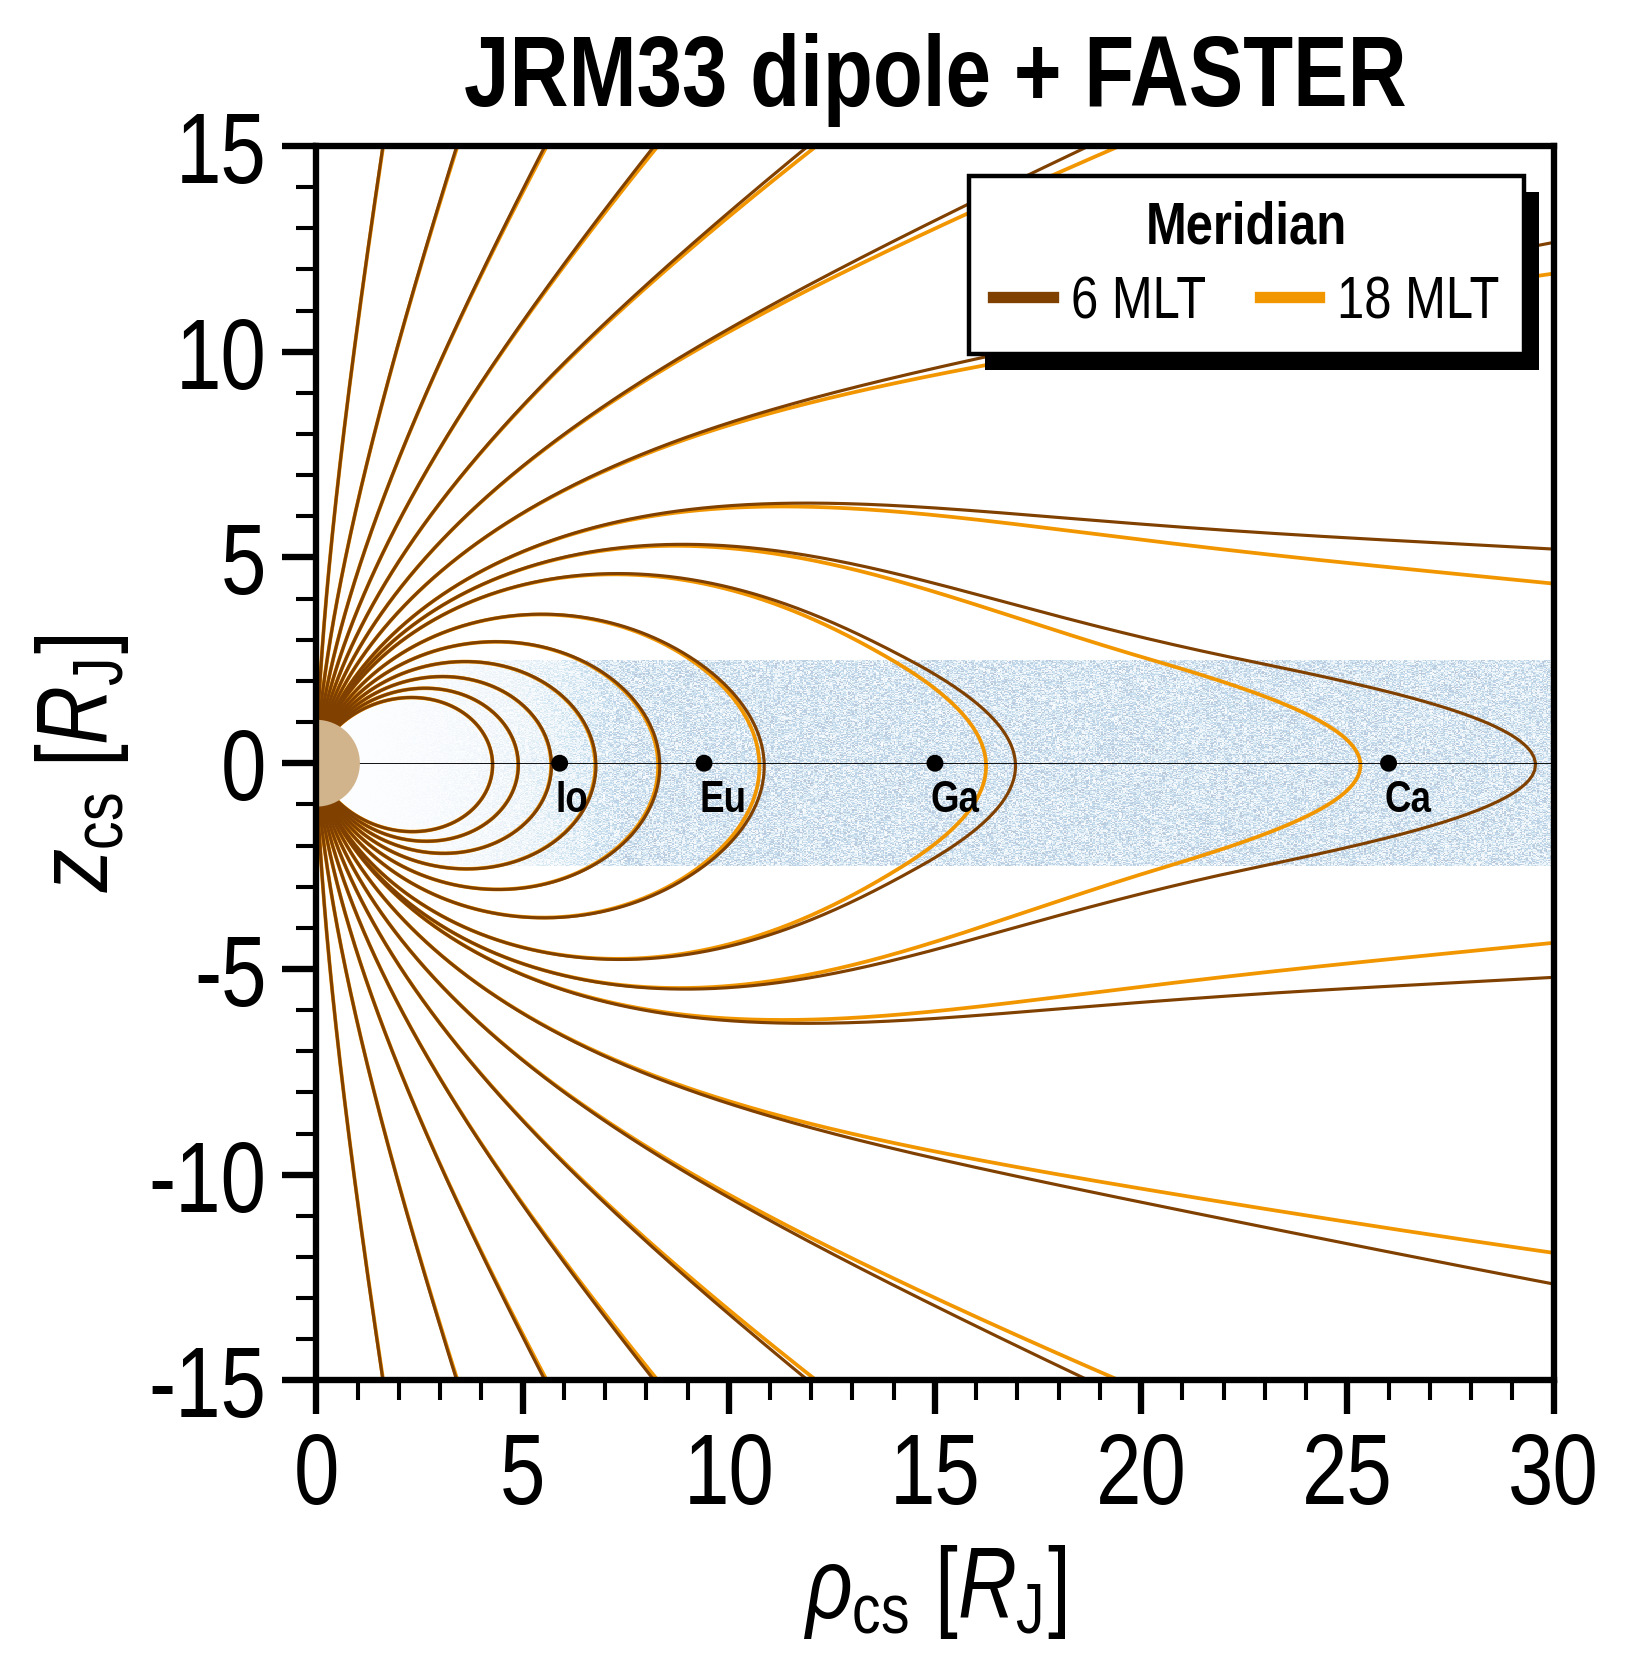

In [22]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.2, 5.), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0, max=30.0,
            ticks=np.arange(0, 30+1, 5),
            ticklabels=np.arange(0, 30+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-15.0, max=15.0,
            ticks=np.arange(-15, 15+1, 5),
            ticklabels=np.arange(-15, 15+1, 5, dtype=int),
            minor_num=5,)

"""for i in range(result_arr0.shape[0]):
    rho_cs = np.sqrt(result_arr0[i, 0, :]**2+result_arr0[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr0[i, 2, :], linewidth=1.0, color=UC.red)"""
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_N[i, 2, :], linewidth=0.83, color=UC.orange2)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_S[i, 2, :], linewidth=0.83, color=UC.orange2)
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_N2[i, 2, :], linewidth=0.69, color=UC.brown)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_S2[i, 2, :], linewidth=0.69, color=UC.brown)
"""for i in range(result_arr3.shape[0]):
    rho_cs = np.sqrt(result_arr3[i, 0, :]**2+result_arr3[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr3[i, 2, :], linewidth=1.0, color=UC.blue)"""
F.ax.axhline(y=0.0, color='k', linewidth=0.2)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
weight = np.clip(np.linspace(0.0, 50.0, noise.shape[1])/7.5, 0.0, 1.0)**2.0
noise *= weight[None, :]
im = F.ax.imshow(
    noise,
    extent=[0.0, 50.0, -2.5, 2.5],
    origin="lower",
    # cmap=F.IDL_blue_white(reverse=True),
    cmap="Blues",
    alpha=0.28,
    interpolation="nearest",
    aspect="auto",
)

"""# Con2020 current sheet shade
rng2 = np.random.default_rng(40)
noise2 = rng2.random((500, 1500))
im2 = F.ax.imshow(
    noise2,
    extent=[7.8, 50.0, -3.6, 3.6],
    origin="lower",
    cmap="Greys",
    alpha=0.15,
    interpolation="nearest",
    aspect="auto",
    zorder=-1,
)"""

# Jupiter
F.ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                          zorder=2, fill=True, clip_on=True))

# Galilean moons
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-0.4, -0.4, -0.4, -0.4]
for i in range(len(radii)):
    F.ax.add_patch(plt.Circle((radii[i], 0), 0.15, color='k',
                              zorder=2, fill=True, clip_on=True))
    F.ax.text(radii[i]-0.11, labelz[i], name[i],
              color='k',
              fontweight='bold',
              fontsize=F.fontsize*0.45,
              verticalalignment='top',
              horizontalalignment='left',)

# Dummy
F.ax.plot([-99, -98], [-99, -98], color=UC.brown,
          linewidth=2.5, label='6 MLT')
F.ax.plot([-99, -98], [-99, -98], color=UC.orange2,
          linewidth=2.5, label='18 MLT')

F.ax.set_title('JRM33 dipole + FASTER', weight='bold')
legend = F.legend(ax_idx=0,
                  ncol=2, markerscale=1.0,
                  loc='upper right',
                  title='Meridian',
                  handlelength=1.0,
                  textcolor=False,
                  fontsize_scale=0.6,
                  handletextpad=0.3)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax, d=0.7)

F.fig.savefig('img/compare_a0_a1_b3_36rj/Galilean_fieldlines_002.png',
              bbox_inches='tight')
F.fig.savefig('img/compare_a0_a1_b3_36rj/Galilean_fieldlines_002.pdf',
              bbox_inches='tight')

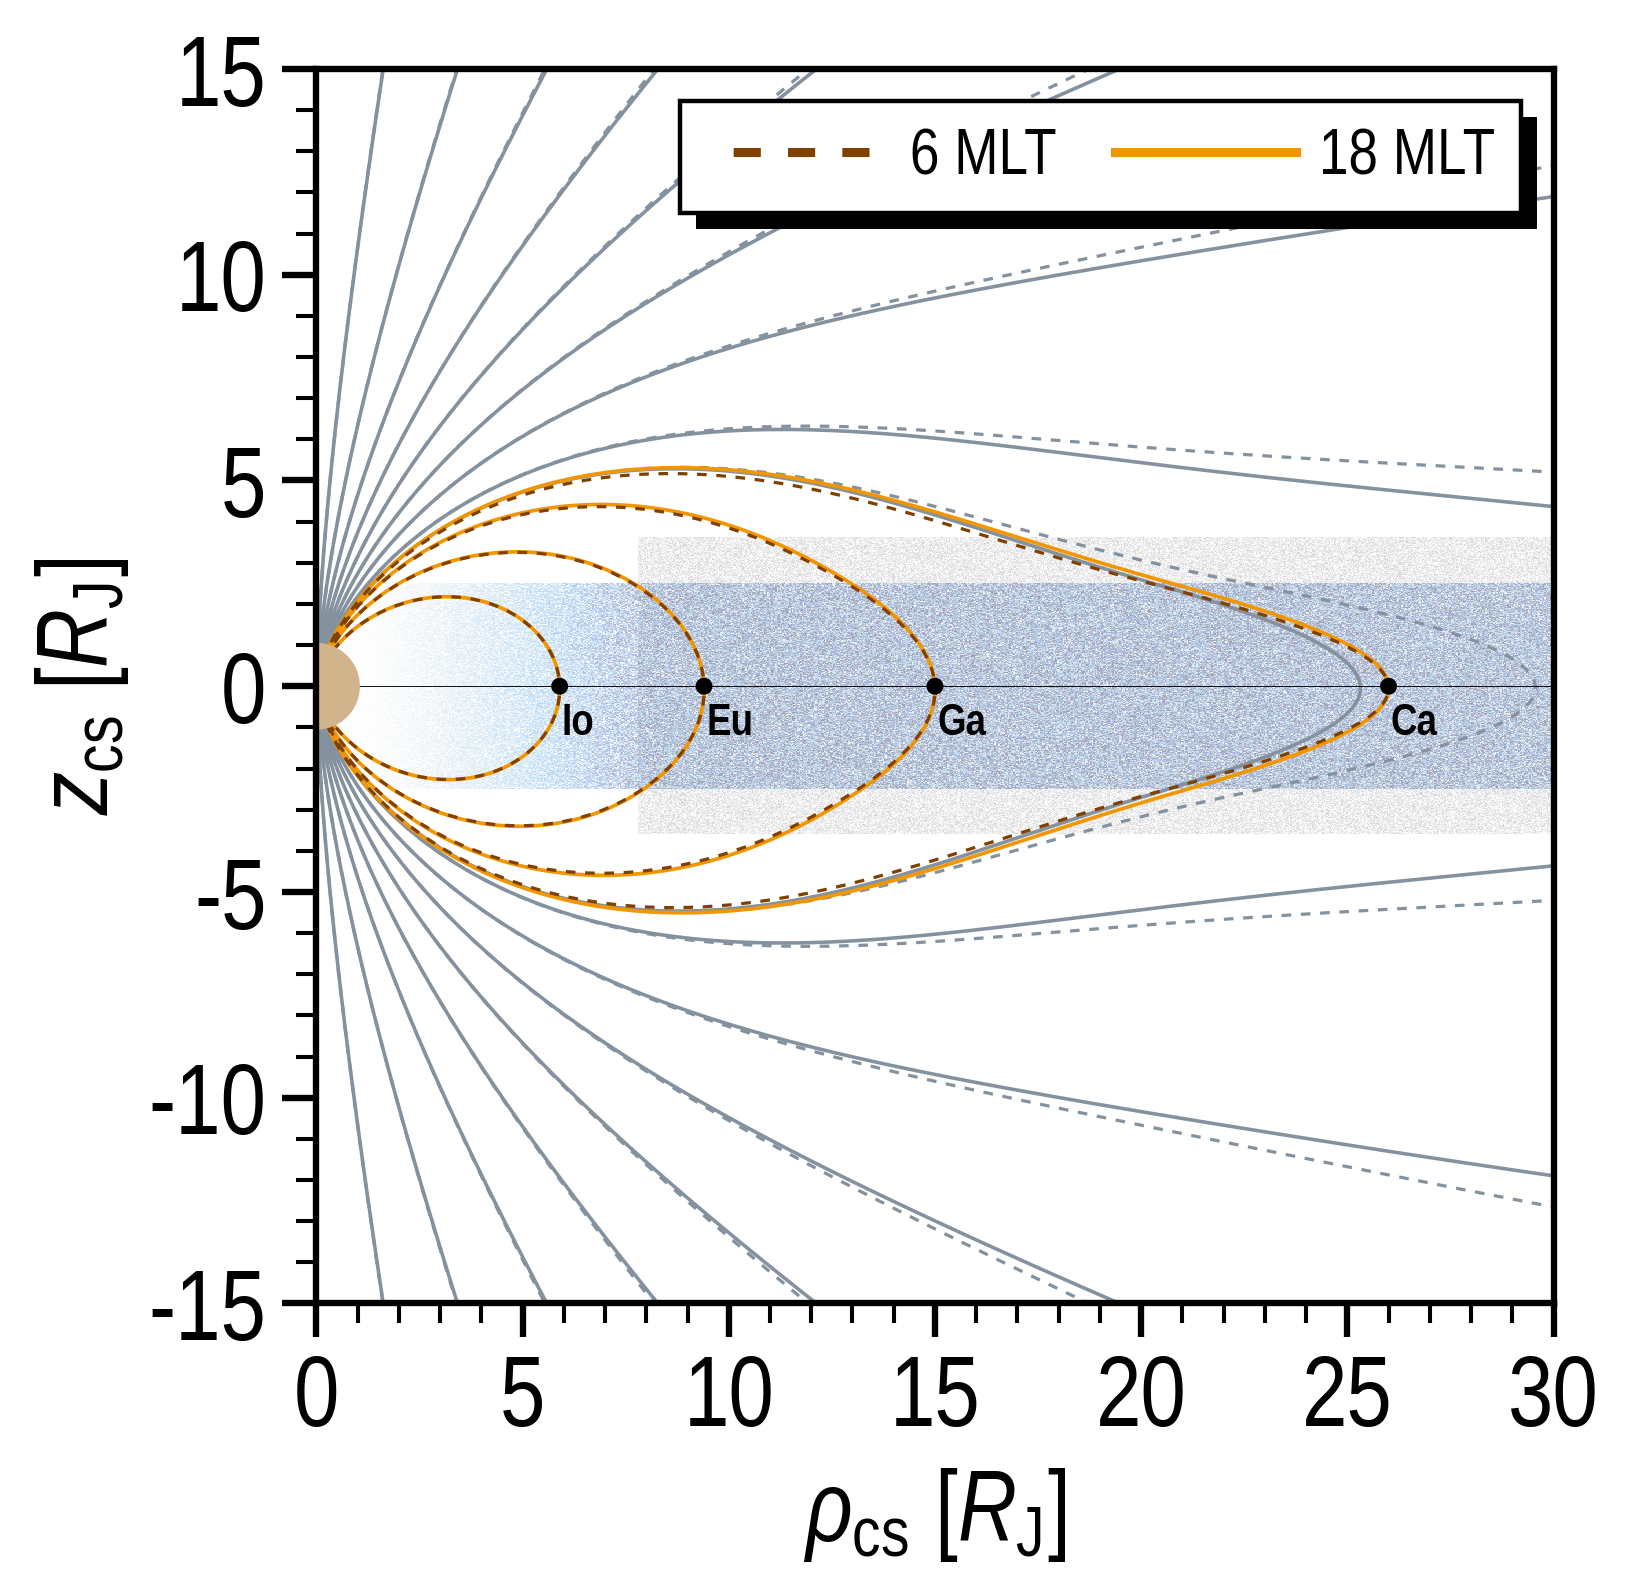

In [23]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.2, 5.), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0, max=30.0,
            ticks=np.arange(0, 30+1, 5),
            ticklabels=np.arange(0, 30+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-15.0, max=15.0,
            ticks=np.arange(-15, 15+1, 5),
            ticklabels=np.arange(-15, 15+1, 5, dtype=int),
            minor_num=5,)

for i in range(result_arr_N.shape[0]-7):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_N[i, 2, :],
              linewidth=0.79, color=UC.gray)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_S[i, 2, :],
              linewidth=0.79, color=UC.gray)
for i in range(result_arr_N2.shape[0]-7):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_N2[i, 2, :],
              linewidth=0.71, linestyle=(3, (3, 3)), color=UC.gray)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_S2[i, 2, :],
              linewidth=0.71, linestyle=(3, (3, 3)), color=UC.gray)
for i in range(result_gal.shape[0]):
    rho_cs = np.sqrt(result_gal2[i, 0, :]**2+result_gal2[i, 1, :]**2)
    F.ax.plot(rho_cs, result_gal2[i, 2, :],
              linewidth=0.81, color=UC.orange2)
for i in range(result_gal.shape[0]):
    rho_cs = np.sqrt(result_gal[i, 0, :]**2+result_gal[i, 1, :]**2)
    F.ax.plot(rho_cs, result_gal[i, 2, :],
              linewidth=0.71, linestyle=(3, (3, 3)), color=UC.brown)
F.ax.axhline(y=0.0, color='k', linewidth=0.2)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
weight = np.clip(np.linspace(0.0, 50.0, noise.shape[1])/7.5, 0.0, 1.0)**2.0
noise *= weight[None, :]
im = F.ax.imshow(
    noise,
    extent=[0.0, 50.0, -2.5, 2.5],
    origin="lower",
    cmap=F.IDL_blue_white(reverse=True),
    alpha=0.28,
    interpolation="nearest",
    aspect="auto",
)

# Con2020 current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax.imshow(
    noise,
    extent=[7.8, 50.0, -3.6, 3.6],
    origin="lower",
    cmap="Greys",
    alpha=0.16,
    interpolation="nearest",
    aspect="auto",
    zorder=-1,
)

# Jupiter
F.ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                          zorder=2, fill=True, clip_on=True))

# Galilean moons
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-0.4, -0.4, -0.4, -0.4]
for i in range(len(radii)):
    F.ax.add_patch(plt.Circle((radii[i], 0), 0.15, color='k',
                              zorder=2, fill=True, clip_on=True))
    F.ax.text(radii[i]+0.05, labelz[i], name[i],
              color='k',
              fontweight='bold',
              fontsize=F.fontsize*0.45,
              verticalalignment='top',
              horizontalalignment='left',)

# Dummy
F.ax.plot([-99, -98], [-99, -98], color=UC.brown,
          linewidth=2.0, linestyle=(3, (3, 3)), label='6 MLT')
F.ax.plot([-99, -98], [-99, -98], color=UC.orange2,
          linewidth=2.0, label='18 MLT')

legend = F.legend(ax_idx=0,
                  ncol=2, markerscale=1.0,
                  loc='upper right',
                  handlelength=2.8,
                  textcolor=False,
                  fontsize_scale=0.65,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax, d=0.7)

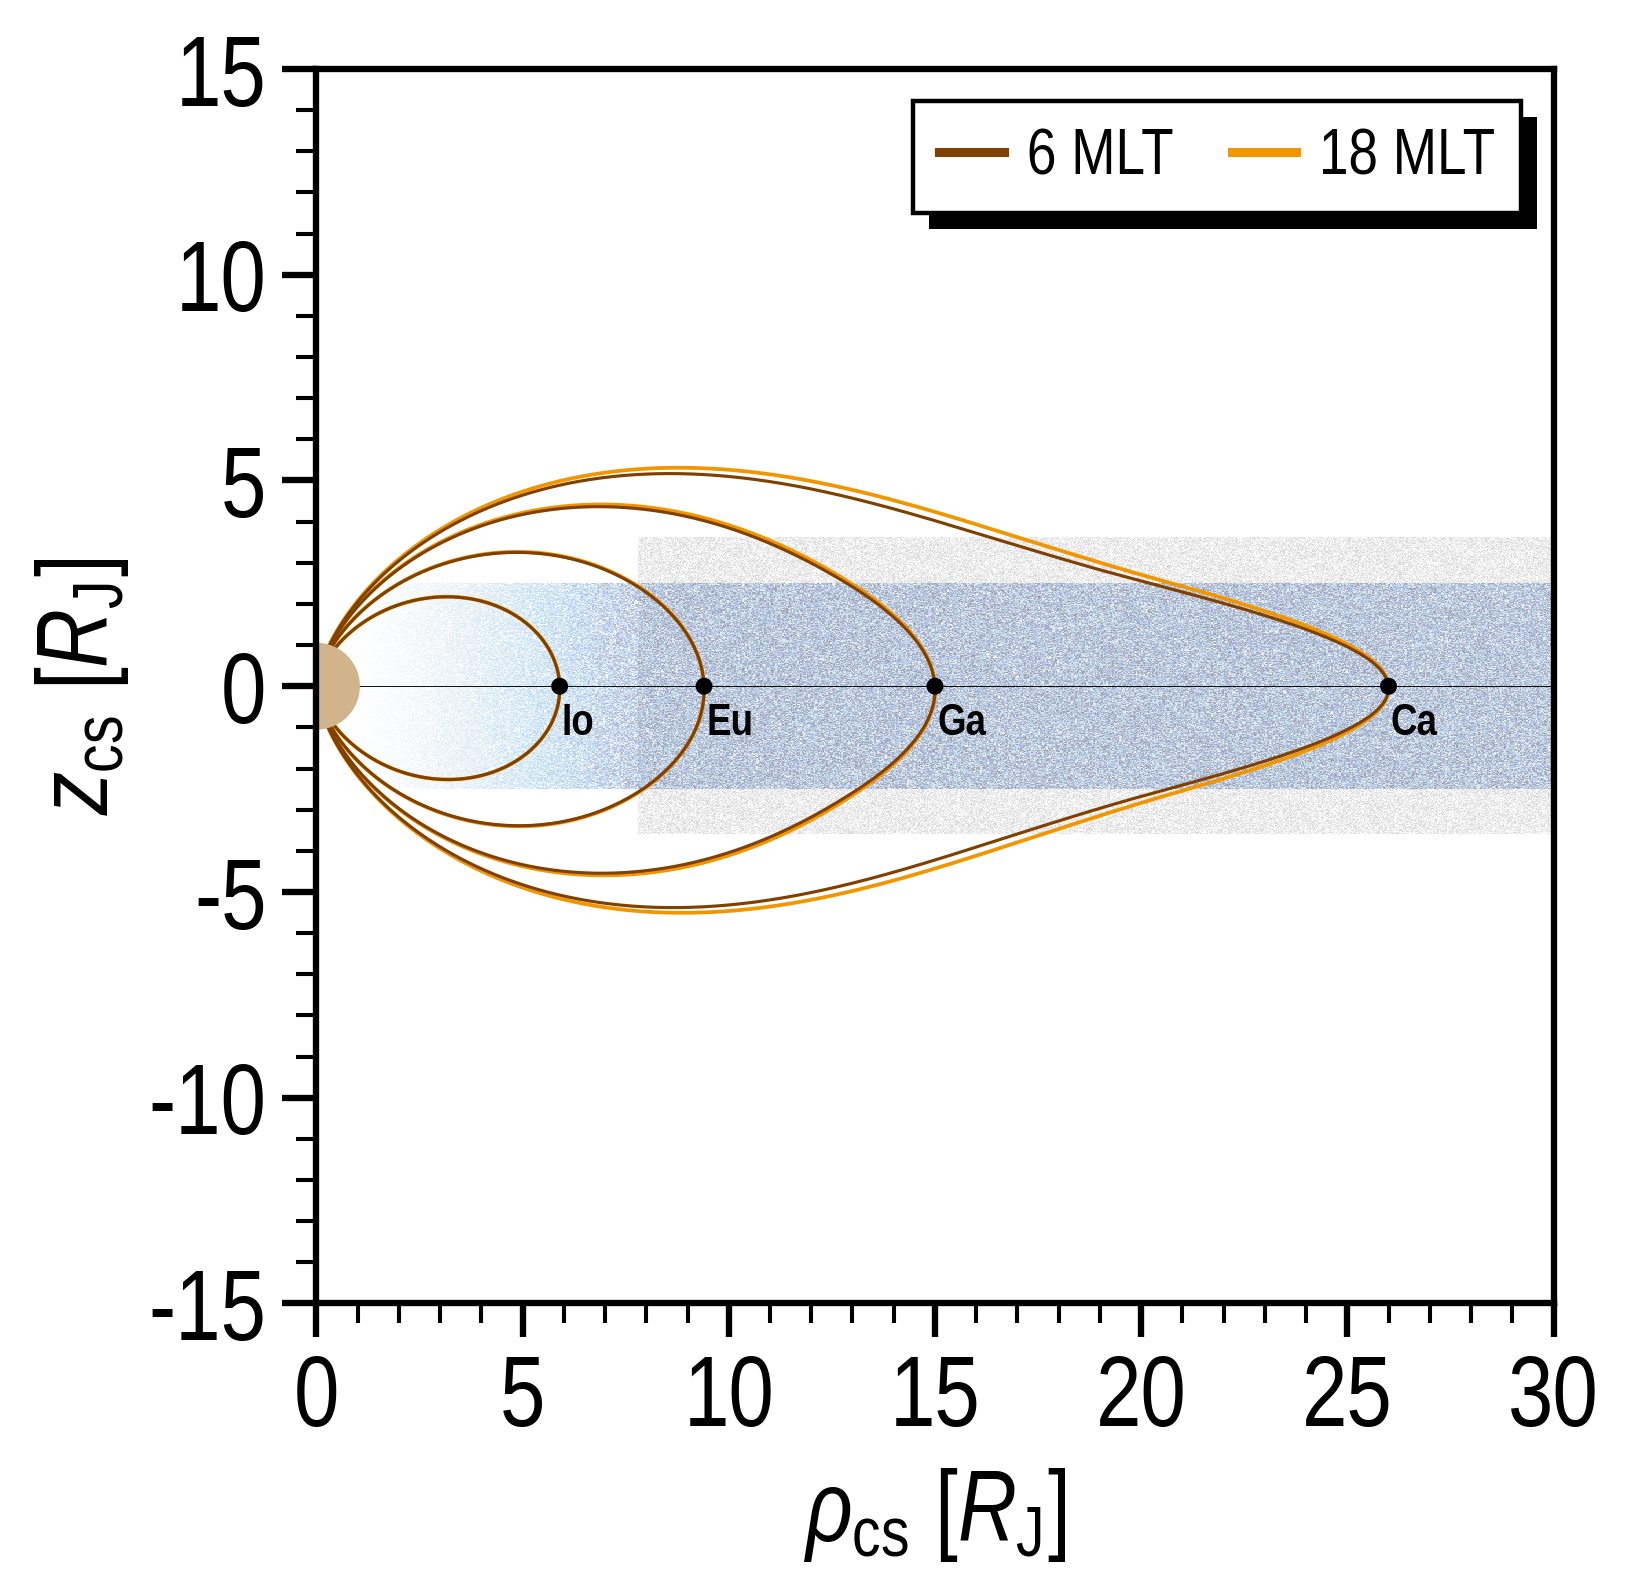

In [24]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.2, 5.), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0, max=30.0,
            ticks=np.arange(0, 30+1, 5),
            ticklabels=np.arange(0, 30+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-15.0, max=15.0,
            ticks=np.arange(-15, 15+1, 5),
            ticklabels=np.arange(-15, 15+1, 5, dtype=int),
            minor_num=5,)

for i in range(result_gal.shape[0]):
    rho_cs = np.sqrt(result_gal2[i, 0, :]**2+result_gal2[i, 1, :]**2)
    F.ax.plot(rho_cs, result_gal2[i, 2, :], linewidth=0.83, color=UC.orange2)
for i in range(result_gal.shape[0]):
    rho_cs = np.sqrt(result_gal[i, 0, :]**2+result_gal[i, 1, :]**2)
    F.ax.plot(rho_cs, result_gal[i, 2, :], linewidth=0.69, color=UC.brown)
F.ax.axhline(y=0.0, color='k', linewidth=0.2)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
weight = np.clip(np.linspace(0.0, 50.0, noise.shape[1])/7.5, 0.0, 1.0)**2.0
noise *= weight[None, :]
im = F.ax.imshow(
    noise,
    extent=[0.0, 50.0, -2.5, 2.5],
    origin="lower",
    cmap=F.IDL_blue_white(reverse=True),
    alpha=0.28,
    interpolation="nearest",
    aspect="auto",
)

# Con2020 current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax.imshow(
    noise,
    extent=[7.8, 50.0, -3.6, 3.6],
    origin="lower",
    cmap="Greys",
    alpha=0.16,
    interpolation="nearest",
    aspect="auto",
    zorder=-1,
)

# Jupiter
F.ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                          zorder=2, fill=True, clip_on=True))

# Galilean moons
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-0.4, -0.4, -0.4, -0.4]
for i in range(len(radii)):
    F.ax.add_patch(plt.Circle((radii[i], 0), 0.15, color='k',
                              zorder=2, fill=True, clip_on=True))
    F.ax.text(radii[i]+0.05, labelz[i], name[i],
              color='k',
              fontweight='bold',
              fontsize=F.fontsize*0.45,
              verticalalignment='top',
              horizontalalignment='left',)

# Dummy
F.ax.plot([-99, -98], [-99, -98], color=UC.brown,
          linewidth=2.0, label='6 MLT')
F.ax.plot([-99, -98], [-99, -98], color=UC.orange2,
          linewidth=2.0, label='18 MLT')

legend = F.legend(ax_idx=0,
                  ncol=2, markerscale=1.0,
                  loc='upper right',
                  handlelength=1.0,
                  textcolor=False,
                  fontsize_scale=0.65,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax, d=0.7)